# **Predictive Maintenance – Machine Failure Prediction Using Machine Learning**

**Project objective**

Build a machine-learning model that predicts whether an industrial machine is likely to fail based on its operating conditions and sensor readings.

In [ ]:
# importing necessary libraries
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from collections import Counter
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [ ]:
# loading data
data=pd.read_csv('/content/drive/MyDrive/machine learning project dataset/ML_Project dataset.csv')
data

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [ ]:
# data inspection

In [ ]:
data.shape

(10000, 14)

In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [ ]:
data.isna().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
data.dtypes

,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [ ]:
data['UDI'].unique()

array([    1,     2,     3, ...,  9998,  9999, 10000], shape=(10000,))

In [ ]:
data['Product ID'].unique()

array(['M14860', 'L47181', 'L47182', ..., 'M24857', 'H39412', 'M24859'],
      shape=(10000,), dtype=object)

In [ ]:
data['Type'].unique()

array(['M', 'L', 'H'], dtype=object)

In [ ]:
data['Air temperature [K]'].unique()

array([298.1, 298.2, 298.3, 298.5, 298.4, 298.6, 298.7, 298.8, 298.9,
       299. , 299.1, 298. , 297.9, 297.8, 297.7, 297.6, 297.5, 297.4,
       297.3, 297.2, 297.1, 297. , 296.9, 296.8, 296.7, 296.6, 296.5,
       296.3, 296.4, 296.2, 296.1, 296. , 295.9, 295.8, 295.7, 295.6,
       295.5, 295.4, 295.3, 299.2, 299.3, 299.5, 299.4, 299.6, 299.7,
       299.8, 299.9, 300. , 300.1, 300.2, 300.3, 300.4, 300.5, 300.6,
       300.7, 300.8, 300.9, 301. , 301.1, 301.2, 301.3, 301.4, 301.5,
       301.6, 301.7, 301.8, 301.9, 302. , 302.1, 302.2, 302.3, 302.4,
       302.5, 302.6, 302.7, 302.8, 302.9, 303. , 303.1, 303.2, 303.3,
       303.4, 303.5, 303.6, 303.7, 303.8, 303.9, 304. , 304.1, 304.2,
       304.3, 304.4, 304.5])

In [ ]:
data['Process temperature [K]'].unique()

array([308.6, 308.7, 308.5, 309. , 308.9, 309.1, 309.2, 309.3, 309.4,
       309.5, 308.8, 308.4, 308.3, 308.2, 308.1, 308. , 307.9, 309.6,
       309.7, 309.8, 309.9, 310. , 310.1, 310.2, 307.8, 307.7, 307.6,
       307.5, 307.4, 307.3, 307.2, 307.1, 307. , 306.9, 306.8, 306.7,
       306.6, 306.5, 306.4, 306.3, 306.2, 306.1, 306. , 305.9, 305.8,
       305.7, 310.3, 310.4, 310.5, 310.6, 310.7, 310.8, 310.9, 311. ,
       311.1, 311.2, 311.3, 311.4, 311.5, 311.6, 311.7, 311.8, 311.9,
       312. , 312.1, 312.2, 312.3, 312.4, 312.5, 312.6, 312.7, 312.8,
       313. , 313.1, 312.9, 313.2, 313.3, 313.4, 313.5, 313.6, 313.8,
       313.7])

In [ ]:
data['Rotational speed [rpm]'].unique()

array([1551, 1408, 1498, 1433, 1425, 1558, 1527, 1667, 1741, 1782, 1423,
       1339, 1742, 2035, 1542, 1311, 1410, 1306, 1632, 1375, 1450, 1581,
       1758, 1561, 1861, 1512, 1811, 1439, 1693, 1798, 1419, 1665, 1559,
       1452, 1379, 1350, 1362, 1368, 1372, 1472, 1489, 1843, 1418, 1412,
       2861, 1383, 1497, 1565, 1691, 1477, 1513, 1661, 1378, 1393, 1592,
       1829, 1812, 1523, 1394, 1679, 1466, 1924, 1369, 1601, 1461, 1455,
       1398, 1402, 1445, 1453, 1469, 1422, 1804, 1436, 1544, 1487, 1753,
       1830, 1727, 1622, 1351, 1575, 1750, 1529, 1852, 1991, 1555, 1441,
       1591, 1621, 1572, 1872, 1499, 1486, 1680, 1431, 1564, 1599, 1707,
       1467, 1310, 1546, 1560, 1329, 1413, 1587, 1473, 1737, 1430, 1711,
       1420, 1297, 1449, 1268, 1511, 1778, 1407, 1391, 1612, 1515, 1463,
       1584, 1850, 1528, 1987, 1495, 1478, 1471, 1282, 1586, 1468, 1440,
       1733, 1458, 1318, 1610, 1462, 1382, 1618, 1988, 1304, 1475, 1824,
       1342, 1485, 1446, 1301, 1606, 1539, 1666, 16

In [ ]:
data['Torque [Nm]'].unique()

array([42.8, 46.3, 49.4, 39.5, 40. , 41.9, 42.4, 40.2, 28.6, 28. , 23.9,
       44.3, 51.1, 30. , 19.6, 48.4, 46.6, 45.6, 54.5, 32.5, 42.7, 44.8,
       30.7, 25.7, 37.3, 23.3, 39. , 24.6, 44.2, 30.1, 48.2, 25.5, 48.3,
       34.7, 48.6, 36.7, 39.2, 50.7, 52.5, 45.4, 50.8, 49.1, 48.5, 47.5,
       25.8, 53.9, 44.1,  4.6, 54.9, 43.8, 35.1, 40.7, 40.3, 29.5, 54.4,
       52.6, 38.2, 22.9, 25.9, 38.6, 45.1, 28.7, 32.4, 65.7, 22.6, 45.5,
       44.4, 35. , 32.3, 46.7, 47.9, 41.3, 51.5, 37.9, 49.9, 40.8, 40.1,
       47.6, 26.8, 43.9, 31.8, 45.2, 24.9, 27.1, 43. , 31.9, 52.2, 35.3,
       29.9, 32.7, 25. , 20.7, 40.6, 40.5, 43.4, 31.1, 46.8, 34.1, 22.5,
       43.5, 29.4, 45.7, 33. , 28.1, 44.7, 41.2, 32.2, 60.5, 46.5, 34.3,
       41.1, 27.7, 43.2, 49.6, 53. , 28.5, 55.3, 55.8, 36.1, 35.2, 28.2,
       50.5, 33.6, 48. , 39.9, 37.6, 41. , 27. , 36.2, 19.8, 46. , 47. ,
       60.7, 52.3, 35.5, 43.6, 26. , 32.6, 42.9, 62.3, 59.1, 20.8, 33.7,
       58.3, 21.4, 50.2, 49.8, 24.2, 48.1, 30.6, 56

In [ ]:
data['Tool wear [min]'].unique()

array([  0,   3,   5,   7,   9,  11,  14,  16,  18,  21,  24,  29,  34,
        37,  40,  42,  44,  47,  50,  55,  58,  63,  65,  68,  70,  73,
        75,  77,  82,  84,  86,  89,  91,  93,  95,  98, 101, 104, 106,
       111, 113, 115, 117, 120, 125, 128, 130, 133, 135, 140, 143, 145,
       147, 152, 154, 156, 158, 160, 162, 165, 167, 169, 172, 174, 177,
       179, 181, 184, 189, 191, 193, 196, 198, 200, 202, 204, 206, 208,
         2,   4,  13,  15,  17,  20,  25,  27,  30,  33,  35,  53,  57,
        59,  61,  66,  72,  80,  92,  97,  99, 103, 108, 110, 112, 114,
       116, 118, 122, 124, 126, 132, 138, 148, 150, 155, 157, 159, 161,
       164, 186, 188, 194, 203, 211, 214, 216, 218,   8,  10,  22,  32,
        39,  41,  43,  45,  49,  54,  67,  69,  74,  76,  81,  96, 105,
       107, 119, 137, 142, 144, 146, 151, 153, 166, 168, 170, 173, 175,
       183, 185, 190, 195, 197, 209, 212,  19,  51,  56,  78,  83,  85,
        88,  90,  94, 109, 131, 134, 136, 192, 199, 201, 205, 21

In [ ]:
data['Machine failure'].unique()

array([0, 1])

In [ ]:
data['TWF'].unique()

array([0, 1])

In [ ]:
data['HDF'].unique()

array([0, 1])

In [ ]:
data['PWF'].unique()

array([0, 1])

In [ ]:
data['OSF'].unique()

array([0, 1])

In [ ]:
data['RNF'].unique()

array([0, 1])

In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
# removing unwanted columns
data.drop(columns=['UDI','Product ID','TWF','HDF','PWF','OSF','RNF'],inplace=True)

In [ ]:
data.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [ ]:
data.shape

(10000, 7)

In [ ]:
data.columns

Index(['Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Machine failure'],
      dtype='object')

In [ ]:
# mapping 'Type' column to convert into int type
data['Type']=data['Type'].map({'M':1,'L':2,'H':3})

In [ ]:
data['Type'].unique()

array([1, 2, 3])

In [ ]:
data.dtypes

,0
Type,int64
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64


In [ ]:
# assigning features and target to x and y
x = data.drop('Machine failure',axis=1)
y = data['Machine failure']

In [ ]:
# train test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state = 87)

In [ ]:
Counter(y_train)

Counter({0: 7731, 1: 269})

# Logistic Regression

In [ ]:
# creating model
lr_model = LogisticRegression()
lr_model.fit(x_train, y_train)


LogisticRegression()

In [ ]:
# predicting y_test using x_test
lr_pred = lr_model.predict(x_test)
pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : lr_pred
})

,Actual,Predicted
865,0,0
796,0,0
3430,0,0
504,0,0
2308,0,0
...,...,...
1887,0,0
6174,0,0
2270,0,0
2012,0,0


In [ ]:
# training score
lr_model.score(x_train,y_train)

0.97

In [ ]:
# testing score
lr_model.score(x_test,y_test)

0.9705

In [ ]:
# accuracy score
accuracy_score(y_test,lr_pred)

0.9705

<Axes: >

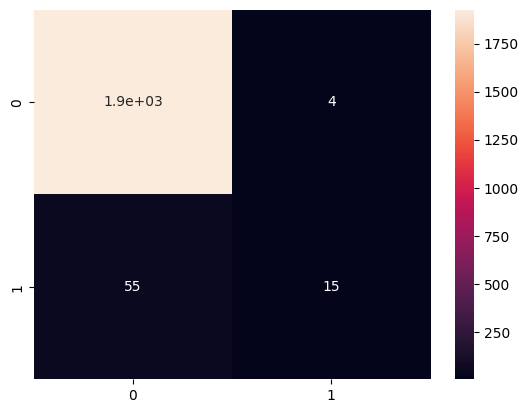

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, lr_pred)
cm
sns.heatmap(cm, annot = True)

In [ ]:
# classification report
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1930
           1       0.79      0.21      0.34        70

    accuracy                           0.97      2000
   macro avg       0.88      0.61      0.66      2000
weighted avg       0.97      0.97      0.96      2000



# Decision Tree Classifier

In [ ]:
# creating model
dt_model = DecisionTreeClassifier(max_depth=11)
dt_model.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=11)

In [ ]:
# predicting y_test using x_test
dt_pred = dt_model.predict(x_test)
pd.DataFrame({'Actual' : y_test, 'Predicted' : dt_pred})

,Actual,Predicted
865,0,0
796,0,0
3430,0,0
504,0,0
2308,0,0
...,...,...
1887,0,0
6174,0,0
2270,0,0
2012,0,0


In [ ]:
# training score
dt_model.score(x_train,y_train)

0.99575

In [ ]:
# testing score
dt_model.score(x_test,y_test)

0.9825

In [ ]:
# accuracy score
accuracy_score(y_test,dt_pred)

0.9825

<Axes: >

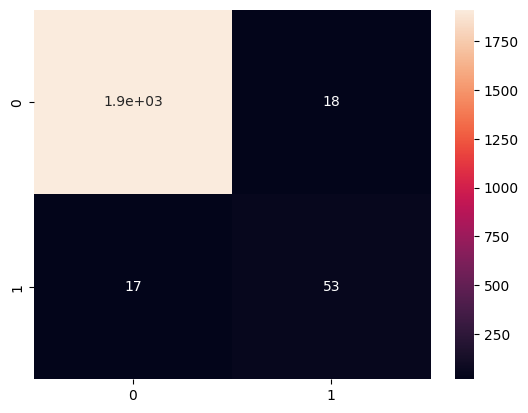

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, dt_pred)
cm
sns.heatmap(cm,annot=True)

In [ ]:
# classification report
print(classification_report(y_test,dt_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1930
           1       0.75      0.76      0.75        70

    accuracy                           0.98      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.98      0.98      0.98      2000



# Random Forest Classifier

In [ ]:
# creating model
rf_model = RandomForestClassifier(n_estimators = 50, max_depth = 7, random_state=89)
rf_model.fit(x_train, y_train)

RandomForestClassifier(max_depth=7, n_estimators=50, random_state=89)

In [ ]:
# predicting y_test using x_test
rf_pred = rf_model.predict(x_test)
pd.DataFrame({'Actual' : y_test, 'Predicted' : rf_pred})

,Actual,Predicted
865,0,0
796,0,0
3430,0,0
504,0,0
2308,0,0
...,...,...
1887,0,0
6174,0,0
2270,0,0
2012,0,0


In [ ]:
# training score
rf_model.score(x_train,y_train)

0.985125

In [ ]:
# testing score
rf_model.score(x_test,y_test)

0.978

In [ ]:
# accuracy score
accuracy_score(y_test,rf_pred)

0.978

<Axes: >

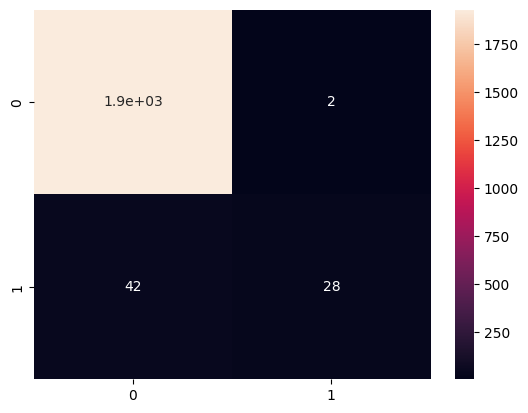

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, rf_pred)
cm
sns.heatmap(cm,annot=True)

In [ ]:
# classification report
print(classification_report(y_test,rf_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1930
           1       0.93      0.40      0.56        70

    accuracy                           0.98      2000
   macro avg       0.96      0.70      0.77      2000
weighted avg       0.98      0.98      0.97      2000



# KNN Classifier

In [ ]:
# creating model
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
# predicting y_test using x_test
knn_pred = knn_model.predict(x_test)
pd.DataFrame({'Actual' : y_test, 'Predicted' : knn_pred})

,Actual,Predicted
865,0,0
796,0,0
3430,0,0
504,0,0
2308,0,0
...,...,...
1887,0,0
6174,0,0
2270,0,0
2012,0,0


In [ ]:
# training score
knn_model.score(x_train, y_train)

0.977125

In [ ]:
# testing score
knn_model.score(x_test, y_test)

0.966

In [ ]:
# accuracy score
accuracy_score(y_test, knn_pred)

0.966

<Axes: >

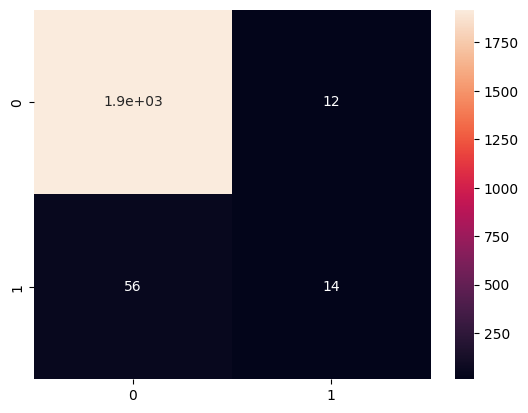

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, knn_pred)
cm
sns.heatmap(cm, annot = True)

In [ ]:
# classification report
print(classification_report(y_test, knn_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1930
           1       0.54      0.20      0.29        70

    accuracy                           0.97      2000
   macro avg       0.76      0.60      0.64      2000
weighted avg       0.96      0.97      0.96      2000



# SVC

In [ ]:
# creating model
svc_model = SVC(kernel = 'linear', C = 3, gamma = 'scale')
svc_model.fit(x_train, y_train)

SVC(C=3, kernel='linear')

In [ ]:
# predicting y_test using x_test
svc_pred = svc_model.predict(x_test)
pd.DataFrame({'Actual' : y_test, 'Predicted' : svc_pred})

,Actual,Predicted
865,0,0
796,0,0
3430,0,0
504,0,0
2308,0,0
...,...,...
1887,0,0
6174,0,0
2270,0,0
2012,0,0


In [ ]:
# training score
svc_model.score(x_train, y_train)

0.970375

In [ ]:
# testing score
svc_model.score(x_test, y_test)

0.9705

In [ ]:
# accuracy score
accuracy_score(y_test, svc_pred)

0.9705

<Axes: >

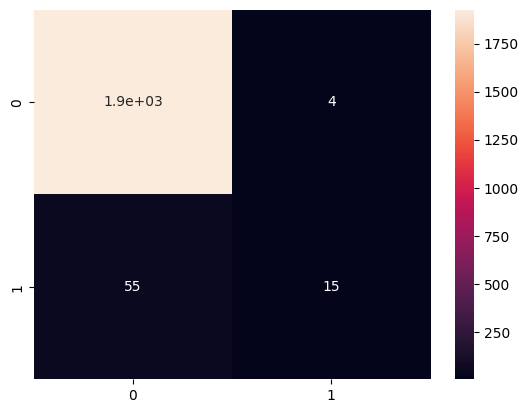

In [ ]:
# confussion matrix
cm = confusion_matrix(y_test, svc_pred)
cm
sns.heatmap(cm, annot = True)

In [ ]:
# classification report
print(classification_report(y_test, svc_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1930
           1       0.79      0.21      0.34        70

    accuracy                           0.97      2000
   macro avg       0.88      0.61      0.66      2000
weighted avg       0.97      0.97      0.96      2000



In [ ]:
# combining scores of all types of algorithms performed

In [ ]:
lr_training_score = lr_model.score(x_train, y_train)
lr_testing_score = lr_model.score(x_test, y_test)
lr_accuracy_score = accuracy_score(y_test, lr_pred)

dt_training_score = dt_model.score(x_train, y_train)
dt_testing_score = dt_model.score(x_test, y_test)
dt_accuracy_score = accuracy_score(y_test, dt_pred)

rf_training_score = rf_model.score(x_train, y_train)
rf_testing_score = rf_model.score(x_test, y_test)
rf_accuracy_score = accuracy_score(y_test, rf_pred)

knn_training_score = knn_model.score(x_train, y_train)
knn_testing_score = knn_model.score(x_test, y_test)
knn_accuracy_score = accuracy_score(y_test, knn_pred)

svc_training_score = svc_model.score(x_train, y_train)
svc_testing_score = svc_model.score(x_test, y_test)
svc_accuracy_score = accuracy_score(y_test, svc_pred)


In [ ]:
pd.DataFrame({
    'Models' : ['LR', 'DTC', 'RFC', 'KNNC', 'SVC'],
    'Training score' : [lr_training_score, dt_training_score, rf_training_score, knn_training_score, svc_training_score],
    'Testing score' : [lr_testing_score, dt_testing_score, rf_testing_score, knn_testing_score, svc_testing_score],
    'Accuracy score' : [lr_accuracy_score, dt_accuracy_score, rf_accuracy_score, knn_accuracy_score, svc_accuracy_score]
})

,Models,Training score,Testing score,Accuracy score
0,LR,0.970000,0.9705,0.9705
1,DTC,0.995750,0.9825,0.9825
2,RFC,0.985125,0.9780,0.9780
3,KNNC,0.977125,0.9660,0.9660
4,SVC,0.970375,0.9705,0.9705


Based on overall results, Decision Tree Classifier (DTC) has the highest testing accuracy.

In [ ]:
x

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,1,298.1,308.6,1551,42.8,0
1,2,298.2,308.7,1408,46.3,3
2,2,298.1,308.5,1498,49.4,5
3,2,298.2,308.6,1433,39.5,7
4,2,298.2,308.7,1408,40.0,9
...,...,...,...,...,...,...
9995,1,298.8,308.4,1604,29.5,14
9996,3,298.9,308.4,1632,31.8,17
9997,1,299.0,308.6,1645,33.4,22
9998,3,299.0,308.7,1408,48.5,25


In [ ]:
# predicting target using new data using Decision Tree Classifier Algorithm (DTC)
new_data=[[1,300.0,308.2,1552,42.0,24]]
print(dt_model.predict(new_data))

[0]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
